In [39]:
import pandas as pd
import numpy as np
import random

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch import optim

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [28]:
train_data = pd.read_csv("../data/logistic_growth_train.csv")
test_data  = pd.read_csv("../data/logistic_growth_test.csv")

In [29]:
train_data.head()

,L0_initial,growth_rate_a,competition_coeff_b,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,...,L_t90,L_t91,L_t92,L_t93,L_t94,L_t95,L_t96,L_t97,L_t98,L_t99
0,33.090710,0.371776,0.009158,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,40.593517,40.587255,40.581092,40.575867,40.572564,40.572313,40.575604,40.578874,40.581583,40.583828
1,47.129551,0.453238,0.001284,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,352.809044,352.843019,352.868486,352.884291,352.890521,352.888510,352.880828,352.871294,352.864964,352.868141
2,19.639865,0.197991,0.001407,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,140.603070,140.609302,140.615048,140.620868,140.627370,140.635091,140.642624,140.649441,140.655610,140.661192
3,30.488209,0.459523,0.003674,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,125.033383,125.044394,125.053031,125.058881,125.061897,125.062401,125.061080,125.058988,125.057546,125.058541
4,47.760681,0.558657,0.002231,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,250.454216,250.461245,250.448120,250.416163,250.369764,250.316377,250.266520,250.233778,250.234799,250.265873


# Basic MLP architecture

In [30]:
# Parameters
param_cols = ['L0_initial', 'growth_rate_a', 'competition_coeff_b']

# Time grid
t_cols = [col for col in train_data.columns if 't_grid' in col]

# Targets
y_cols = [col for col in train_data.columns if 'L_t' in col]

# X = parameters + time grid
X_train = np.concatenate([
    train_data[param_cols].values,
    train_data[t_cols].values
], axis=1)

X_test = np.concatenate([
    test_data[param_cols].values,
    test_data[t_cols].values
], axis=1)

# Y = trajectories
Y_train = train_data[y_cols].values
Y_test = test_data[y_cols].values

print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

X_train shape: (400, 103)
Y_train shape: (400, 100)


In [31]:
scaler_X = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_test  = scaler_X.transform(X_test)

In [32]:
class LogisticMLPDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.FloatTensor(X)
        self.Y = torch.FloatTensor(Y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

train_dataset = LogisticMLPDataset(X_train, Y_train)
test_dataset  = LogisticMLPDataset(X_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [33]:
class LogisticMLP(nn.Module):
    def __init__(self, input_dim=103, hidden_dim=128, output_dim=100):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.network(x)

In [34]:
model = LogisticMLP(input_dim=X_train.shape[1], hidden_dim=128, output_dim=Y_train.shape[1])
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [35]:
epochs = 20

train_losses = []
val_losses = []

for epoch in range(epochs):
    # TRAIN
    model.train()
    total_train_loss = 0
    for X_batch, Y_batch in train_loader:
        optimizer.zero_grad()
        pred = model(X_batch)
        loss = criterion(pred, Y_batch)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # VALIDATION
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            pred = model(X_batch)
            val_loss = criterion(pred, Y_batch)
            total_val_loss += val_loss.item()
    avg_val_loss = total_val_loss / len(test_loader)
    val_losses.append(avg_val_loss)

    # PRINT
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {avg_train_loss:.6f} "
            f"| Val Loss: {avg_val_loss:.6f}"
        )

torch.save(model.state_dict(), "mlp_logistic_growth.pth")
print("\nTraining finished.")

Epoch [1/20] | Train Loss: 14124.776217 | Val Loss: 13628.464600
Epoch [10/20] | Train Loss: 975.389780 | Val Loss: 1276.872681
Epoch [20/20] | Train Loss: 647.565197 | Val Loss: 919.717934

Training finished.


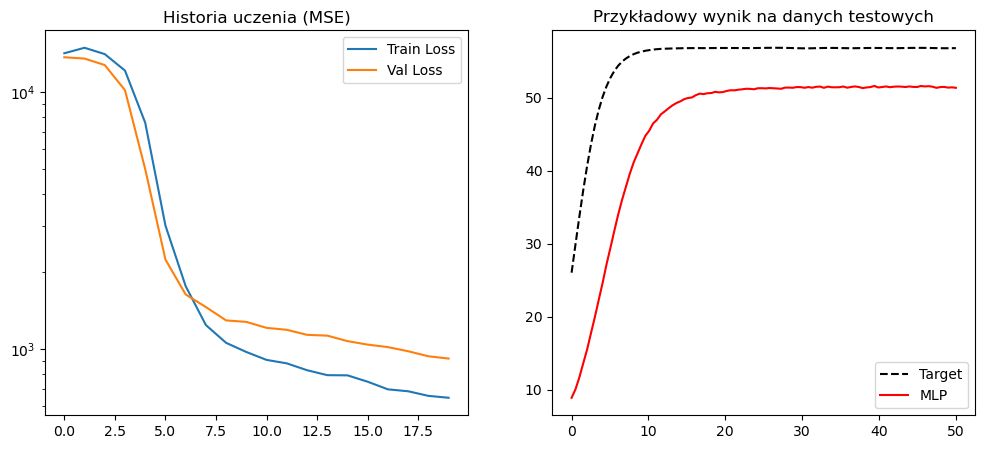

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Wykres błędu
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.yscale('log')
plt.title('Historia uczenia (MSE)')
plt.legend()

# Przykładowa predykcja
plt.subplot(1, 2, 2)
with torch.no_grad():
    sample_X, sample_y = next(iter(test_loader))
    pred = model(sample_X)[0].numpy()
    target = sample_y[0].numpy()
    time_axis = np.linspace(0, 50, len(pred))
    plt.plot(time_axis, target, 'k--', label='Target')
    plt.plot(time_axis, pred, 'r', label='MLP')
    plt.title('Przykładowy wynik na danych testowych')
    plt.legend()

plt.show()

# Random Search

In [ ]:
def train_logistic_mlp(config, train_loader, test_loader, epochs):
    model = LogisticMLP(input_dim=X_train.shape[1], hidden_dim=config['hidden_dim'], output_dim=Y_train.shape[1])
    criterion = nn.MSELoss()

    if config['optimizer'] == 'Adam':
        optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    else:
        optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
        
    history = {'train': [], 'val': []}
    
    for epoch in range(epochs):
        # Training
        model.train()
        t_loss = 0
        for X, y in train_loader:
            optimizer.zero_grad()
            pred = model(X)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            t_loss += loss.item()
        
        # Validation
        model.eval()
        v_loss = 0
        with torch.no_grad():
            for X, y in test_loader:
                v_loss += criterion(model(X), y).item()

        history['train'].append(t_loss / len(train_loader))
        history['val'].append(v_loss / len(test_loader))
        
    return model, history

In [40]:
param_grid = {
    'hidden_dim': [32, 64, 128, 256],          # Szerokość warstw ukrytych w Trunk Net
    'lr': [1e-3, 5e-4, 1e-4, 5e-5],            # Współczynnik uczenia
    'weight_decay': [0.0, 1e-5, 1e-4],         # Regularyzacja L2
    'optimizer': ['Adam', 'AdamW']             # Rodzaj optymalizatora
}
best_val_loss = float('inf')
best_config = None

num_search_trials = 8
print("--- ROZPOCZYNAM RANDOM SEARCH ---")
for i in range(num_search_trials):
    config = {k: random.choice(v) for k, v in param_grid.items()}
    print(f"Próba {i+1}/{num_search_trials} | Konfiguracja: {config}")
    
    # Trenujemy krótko (15 epok), żeby tylko ocenić potencjał konfiguracji
    _, history = train_logistic_mlp(config, train_loader, test_loader, epochs=15)
    final_val = history['val'][-1]
    print(f"-> Wynik po 15 epokach (Val Loss): {final_val:.6f}")
    
    if final_val < best_val_loss:
        best_val_loss = final_val
        best_config = config
print(f"\n[SUKCES] Wybrano najlepszą konfigurację: {best_config}")

--- ROZPOCZYNAM RANDOM SEARCH ---
Próba 1/8 | Konfiguracja: {'hidden_dim': 64, 'lr': 0.0005, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 1072.356621
Próba 2/8 | Konfiguracja: {'hidden_dim': 256, 'lr': 0.0001, 'weight_decay': 1e-05, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 1093.272049
Próba 3/8 | Konfiguracja: {'hidden_dim': 64, 'lr': 0.001, 'weight_decay': 0.0001, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 1147.457848
Próba 4/8 | Konfiguracja: {'hidden_dim': 128, 'lr': 0.001, 'weight_decay': 0.0, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 1101.070435
Próba 5/8 | Konfiguracja: {'hidden_dim': 64, 'lr': 0.0005, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 1158.192169
Próba 6/8 | Konfiguracja: {'hidden_dim': 32, 'lr': 0.0001, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 1121.985451
Próba 7/8 | Konfiguracja: {'hidden_dim': 128, 'lr': 0.001, '

In [43]:
print(f"Trening od nowa na najlepszym zestawie {best_config}")

FINAL_EPOCHS = 100

model = LogisticMLP(input_dim=X_train.shape[1], hidden_dim=best_config['hidden_dim'], output_dim=Y_train.shape[1])

if best_config['optimizer'] == 'Adam':
    optimizer = optim.Adam(model.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])
else:
    optimizer = optim.AdamW(model.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])

criterion = torch.nn.MSELoss()

best_val_loss = float('inf')
final_history = {'train': [], 'val': []}

for epoch in range(FINAL_EPOCHS):
    model.train()
    total_train_loss = 0
    for b_X, b_y in train_loader:
        optimizer.zero_grad()
        output = model(b_X)
        loss = criterion(output, b_y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
        
    # Ewaluacja
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for v_X, v_y in test_loader:
            v_output = model(v_X)
            v_loss = criterion(v_output, v_y)
            total_val_loss += v_loss.item()
            
    avg_train = total_train_loss / len(train_loader)
    avg_val = total_val_loss / len(test_loader)
    
    final_history['train'].append(avg_train)
    final_history['val'].append(avg_val)
    
    # Zapisz model, jeśli jest najlepszy do tej pory (dokładnie jak w Twoim przykładzie)
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model.state_dict(), 'best_logistic_mlp_model.pth')
        status = " [MODEL SAVED]"
    else:
        status = ""
        
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] | Train: {avg_train:.6f} | Val: {avg_val:.6f}{status}")

print(f"\nTrening zakończony. Najlepszy Val Loss: {best_val_loss:.6f}")

Trening od nowa na najlepszym zestawie {'hidden_dim': 64, 'lr': 0.0005, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
Epoch [1/100] | Train: 13992.089017 | Val: 13648.780029 [MODEL SAVED]
Epoch [10/100] | Train: 10033.900222 | Val: 9279.161865 [MODEL SAVED]
Epoch [20/100] | Train: 1172.300716 | Val: 1505.098824 [MODEL SAVED]
Epoch [30/100] | Train: 952.128801 | Val: 1320.289696 [MODEL SAVED]
Epoch [40/100] | Train: 820.905600 | Val: 1183.317871 [MODEL SAVED]
Epoch [50/100] | Train: 721.315836 | Val: 1073.320274 [MODEL SAVED]
Epoch [60/100] | Train: 653.816470 | Val: 988.000023 [MODEL SAVED]
Epoch [70/100] | Train: 614.291154 | Val: 912.682961 [MODEL SAVED]
Epoch [80/100] | Train: 568.835034 | Val: 858.988918
Epoch [90/100] | Train: 525.996280 | Val: 800.046989 [MODEL SAVED]
Epoch [100/100] | Train: 492.588915 | Val: 732.899151 [MODEL SAVED]

Trening zakończony. Najlepszy Val Loss: 732.899151


In [45]:
def plot_mean_and_variance(model, loader, filename="logistic_stats_mlp.png"):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for b_X, b_y in loader:
            preds = model(b_X)
            all_preds.append(preds)
            all_targets.append(b_y)
    
    all_preds = torch.cat(all_preds, dim=0).squeeze()
    all_targets = torch.cat(all_targets, dim=0).squeeze()
    
    mean_pred = all_preds.mean(dim=0).numpy()
    std_pred = all_preds.std(dim=0).numpy()
    mean_target = all_targets.mean(dim=0).numpy()
    std_target = all_targets.std(dim=0).numpy()
    
    t_axis = range(len(mean_pred))
    
    plt.figure(figsize=(12, 6))
    plt.plot(t_axis, mean_target, color='black', label='Średnia Solver ODE', lw=2)
    plt.fill_between(t_axis, mean_target - std_target, mean_target + std_target, 
                     color='black', alpha=0.1, label='Wariancja populacji (Solver)')
    
    plt.plot(t_axis, mean_pred, color='red', linestyle='--', label='Średnia MLP', lw=2)
    plt.fill_between(t_axis, mean_pred - std_pred, mean_pred + std_pred, 
                     color='red', alpha=0.2, label='Wariancja predykcji (MLP)')
    
    plt.title('Statystyka zbiorcza: Dynamika wzrostu populacji $L(t)$')
    plt.xlabel('Czas ($t$)')
    plt.ylabel('Populacja ($L$)')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Plik {filename} został zapisany pomyślnie.")
    plt.show()

In [48]:
def plot_history(history, filename="loss_history_mlp.png"):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train'], label='Błąd Treningowy', color='#1f77b4')
    plt.plot(history['val'], label='Błąd Walidacyjny', color='#ff7f0e')
    plt.yscale('log')
    plt.title('Krzywa uczenia MLP ($dL/dt = aL - bL^2$)')
    plt.xlabel('Epoka')
    plt.ylabel('MSE Loss (Log Scale)')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

def visualize_results(model, loader, num_samples=3, filename="logistic_samples_mlp.png"):
    model.eval()

    X_in, y_true = next(iter(loader))
    X_in, y_true = X_in[:num_samples], y_true[:num_samples]
    
    with torch.no_grad():
        preds = model(X_in)
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))
    
    for i in range(num_samples):
        axes[i, 0].plot(y_true[i].numpy().flatten(), label='Solver ODE (Target)', color='black', lw=2)
        axes[i, 0].plot(preds[i].numpy().flatten(), label='MLP (Prediction)', color='red', linestyle='--')
        axes[i, 0].set_title(f'Przykładowa ewolucja populacji L(t) - Próba {i+1}')
        axes[i, 0].set_xlabel('Kroki czasowe')
        axes[i, 0].set_ylabel('Populacja $L$')
        axes[i, 0].legend()
        
        # Błąd bezwzględny w czasie
        error = torch.abs(y_true[i] - preds[i]).numpy().flatten()
        axes[i, 1].fill_between(range(len(error)), error, color='red', alpha=0.3)
        axes[i, 1].set_title(f'Błąd bezwzględny $|L_{{true}} - L_{{pred}}|$')
        axes[i, 1].set_xlabel('Kroki czasowe')
        
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

Zapisano: loss_history_mlp.png


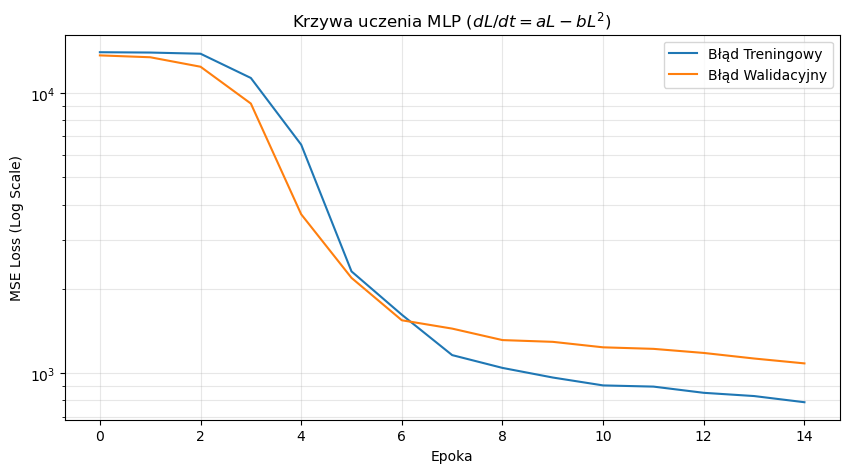

Zapisano: logistic_samples_mlp.png


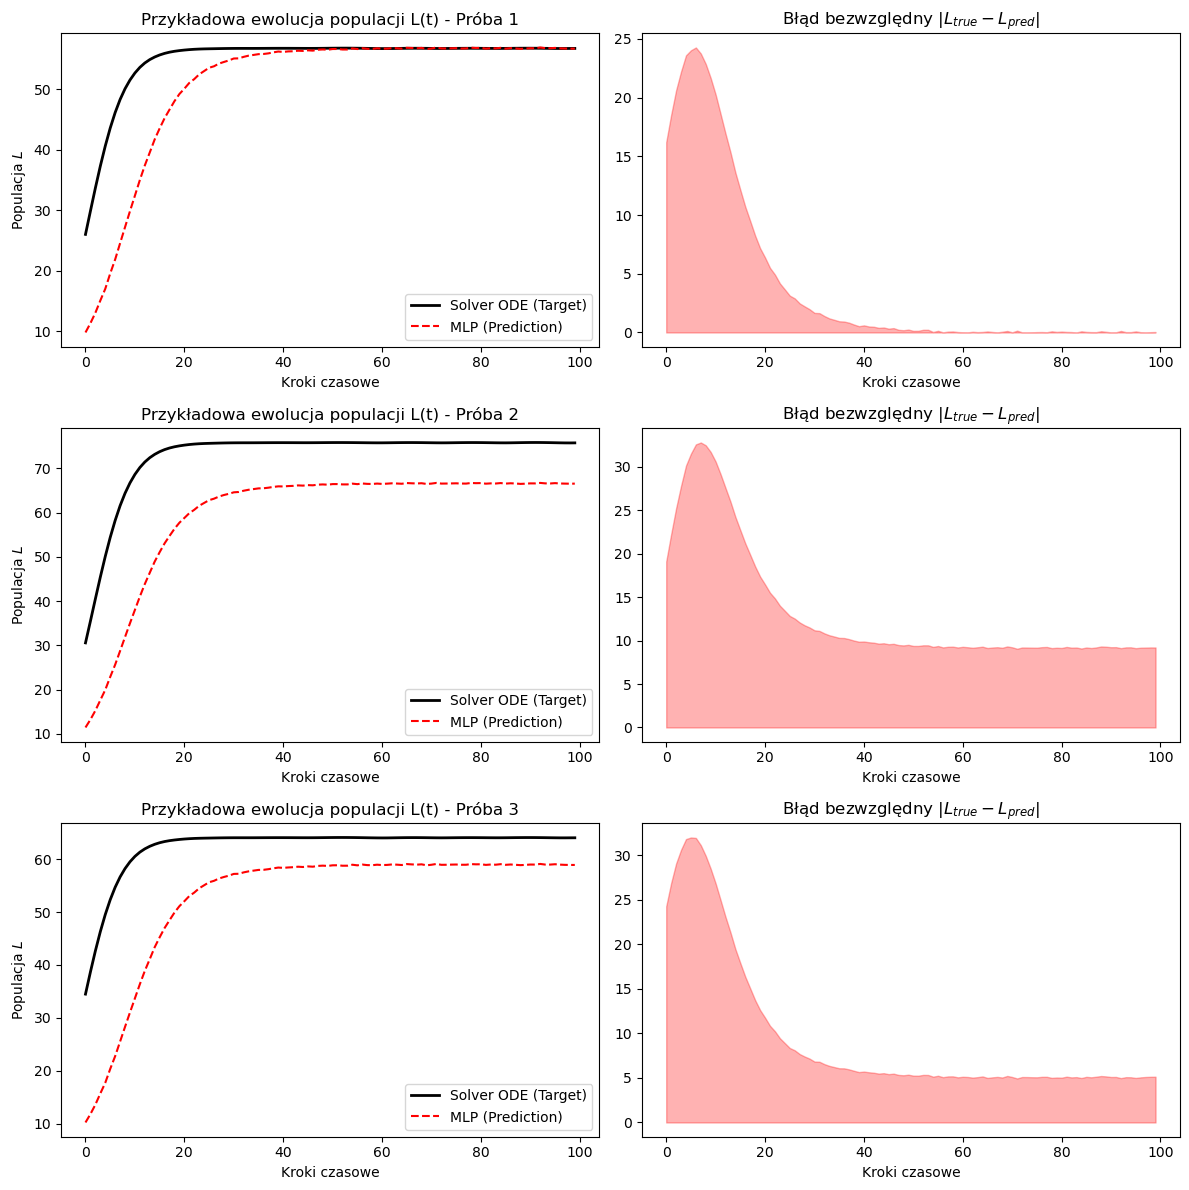

Plik logistic_stats_mlp.png został zapisany pomyślnie.


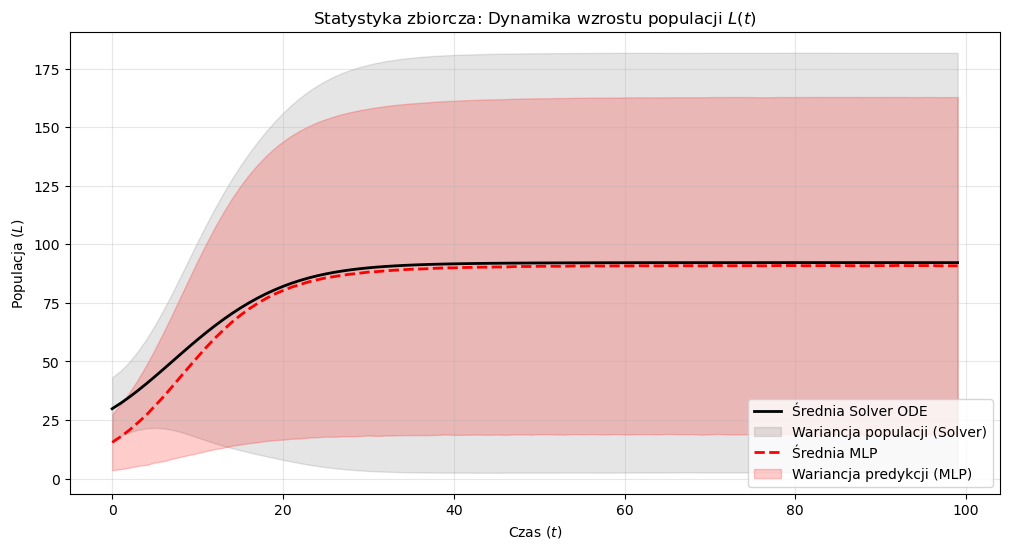

In [49]:
plot_history(history)
visualize_results(model, test_loader)
plot_mean_and_variance(model, test_loader)